In [392]:
%pip install pandas numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [393]:
import pandas as pd
import numpy as np

In [394]:
format_month = lambda x: f'0{x}' if x <= 9 else f'{x}'

data_folder = 'data'
path = '_producao_Mar.csv'
years = {
    '2023_': [format_month(x) for x in range(1, 13)],
    '2024_': [format_month(x) for x in range(1, 13)],
    '2025_': [format_month(x) for x in range(1, 9)]
}
columns_list = []

In [395]:
years

{'2023_': ['01',
  '02',
  '03',
  '04',
  '05',
  '06',
  '07',
  '08',
  '09',
  '10',
  '11',
  '12'],
 '2024_': ['01',
  '02',
  '03',
  '04',
  '05',
  '06',
  '07',
  '08',
  '09',
  '10',
  '11',
  '12'],
 '2025_': ['01', '02', '03', '04', '05', '06', '07', '08']}

In [396]:
df_final = pd.DataFrame()

In [397]:
columns_to_remove = ['Estado', 'Bacia', 'Nome Poço ANP', 'Nome Poço Operador', 'Campo',
       'Operador', 'Número do Contrato', 'Instalação Destino', 'Tipo Instalação', 'Período da Carga', 
       'Corrente', 'Data de atualização', 'Fração de Destilados|Lev|Cort', 'Fração de Destilados|Lev|Vol', 
       'Fração de Destilados|Méd|Corte', 'Fração de Destilados|Méd|Vol', 'Fração de Destilados|Pes|Corte', 'Fração de Destilados|Pes|Vol', '% em Volumes Metano',
       '% em Volumes Etano', '% em Volumes Propano', '% em Volumes Iso-Butano',
       '% em Volumes Butano', '% em Volumes Iso-Pentano',
       '% em Volumes n-Pentano', '% em Volumes Hexanos',
       '% em Volumes Heptanos', '% em Volumes Octanos', '% em Volumes Nonanos',
       '% em Volumes Decanos', '% em Volumes Undecanos',
       '% em Volumes Oxigênio', '% em Volumes Nitrogênio',
       '% em Volumes Gás Carbônico', 'Gás Natural (Mm³/dia) Assoc', 'Gás Natural (Mm³/dia) N Assoc']

In [398]:
for year in years:
    for month in years[year]:
        df = pd.read_csv(data_folder + '/' + year + month + path, sep=';', encoding='latin1')
        df.dropna()
        df = df.drop(columns_to_remove, axis=1)
        df_final = pd.concat([df_final, df])

In [399]:
df_final

,Período,Óleo (bbl/dia),Condensado (bbl/dia),Petróleo (bbl/dia),Gás Natural (Mm³/dia) Total,Volume Gás Royalties (m³/mês),Água (bbl/dia),Tempo de Produção (hs por mês),Grau API,Densidade GLP Gás,Densidade GLP Líquido,PCS GP(kJ/m³)
0,2023/01,"10597,4769",0,"10597,4769","56,5923","1355,916","4800,2166",744,"33,3","2,02232","530,74669","40592,3314"
1,2023/01,"3245,1189",0,"3245,1189","16,1271","386,394","8032,5534",744,"33,3","2,02232","530,74669","40592,3314"
2,2023/01,0,0,0,0,0,0,0,"33,3","2,02232","530,74669","40592,3314"
3,2023/01,"2116,3271",0,"2116,3271","25,6074","613,536","5439,4737",714,"33,3","2,02232","530,74669","40592,3314"
4,2023/01,"1978,3072",0,"1978,3072","16,1911","387,928","5187,5167",712,"33,3","2,02232","530,74669","40592,3314"
...,...,...,...,...,...,...,...,...,...,...,...,...
996,2025/08,"1374,4294",0,"1374,4294",",9751","25,13","32,1202",741,"19,2","2,06677","536,03956","40529,9208"
997,2025/08,0,0,0,0,0,0,0,"19,2","2,06677","536,03956","40529,9208"
998,2025/08,"979,8785",0,"979,8785","1,3825","35,633","136,3452",736,"19,2","2,06677","536,03956","40529,9208"
999,2025/08,"2460,3767",0,"2460,3767","16,0628","413,996","30,462",742,"19,2","2,06677","536,03956","40529,9208"


In [400]:
for col in df_final.columns:
    df_final[col] = df_final[col].astype(str)
    
    df_final[col] = df_final[col].str.replace(',', '.', regex=False)
    
    df_final[col] = np.where(
        df_final[col].str.startswith('.'),
        '0' + df_final[col],
        df_final[col]
    )

    df_final[col] = np.where(
        df_final[col].str.match('nan', case=False),
        np.nan,
        df_final[col]
    )
    
    try:
        df_final[col] = pd.to_numeric(df_final[col]) 
    except:
        pass

In [401]:
df_final.dropna(inplace=True)

In [402]:
df_final.columns

Index(['Período', 'Óleo (bbl/dia)', 'Condensado (bbl/dia)',
       'Petróleo (bbl/dia)', 'Gás Natural (Mm³/dia) Total',
       'Volume Gás Royalties (m³/mês)', 'Água (bbl/dia)',
       'Tempo de Produção (hs por mês)', 'Grau API', 'Densidade GLP Gás',
       'Densidade GLP Líquido', 'PCS GP(kJ/m³)'],
      dtype='object')

In [403]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [404]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

In [405]:
target_column = 'Petróleo (bbl/dia)'
ignore_columns = ['Período', 'Gás Natural (Mm³/dia) Total', 'Condensado (bbl/dia)',
       'Volume Gás Royalties (m³/mês)',  
       'Grau API', 'Densidade GLP Líquido', 'PCS GP(kJ/m³)']

In [406]:
sample_df = df_final.sample(frac=.1, random_state=1)
sample_df.drop_duplicates(inplace=True)
for col in sample_df.columns:
    if col not in ignore_columns and col != target_column:
        Q1 = sample_df[col].quantile(0.25)
        Q3 = sample_df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        sample_df = sample_df[(sample_df[col] >= lower_bound) & (sample_df[col] <= upper_bound)]

sample_df

,Período,Óleo (bbl/dia),Condensado (bbl/dia),Petróleo (bbl/dia),Gás Natural (Mm³/dia) Total,Volume Gás Royalties (m³/mês),Água (bbl/dia),Tempo de Produção (hs por mês),Grau API,Densidade GLP Gás,Densidade GLP Líquido,PCS GP(kJ/m³)
808,2023/08,306.5333,0.0000,306.5333,11.4868,90.401,0.0000,507,28.70,2.03835,532.62903,36744.1567
300,2024/01,0.0000,0.0000,0.0000,0.0000,0.000,0.0000,0,13.42,2.10444,540.56115,37950.8768
548,2023/01,156.6019,0.0000,156.6019,2.1743,67.403,1286.1633,639,30.23,2.12184,542.65437,36715.5245
655,2024/07,118.8076,0.0000,118.8076,4.6356,65.854,0.2735,685,30.20,2.00144,528.22646,38798.0539
546,2024/06,217.8568,0.0000,217.8568,8.1110,61.308,0.0000,464,28.70,2.05769,534.93806,38035.1618
...,...,...,...,...,...,...,...,...,...,...,...,...
479,2024/03,1130.3411,0.0000,1130.3411,43.0598,522.883,271.1959,446,30.20,2.00144,528.22646,38798.0539
714,2025/08,798.6669,0.0000,798.6669,2.1316,54.940,7136.6376,738,19.20,2.06677,536.03956,40529.9208
447,2023/01,0.0000,799.5276,799.5276,1296.2825,40184.758,112.8627,744,54.80,2.02668,531.22216,38650.4798
440,2024/05,1923.7345,0.0000,1923.7345,26.8265,830.537,4049.3683,598,23.40,2.03930,532.75200,39260.1913


In [413]:
X = sample_df.drop(ignore_columns + [target_column], axis=1)
y = sample_df[target_column]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [414]:
X_train

,Óleo (bbl/dia),Água (bbl/dia),Tempo de Produção (hs por mês),Densidade GLP Gás
617,6788.0666,0.6789,542,2.03835
31,366.2063,4714.9787,336,2.04342
756,78.7677,11.0757,17,2.03930
740,5628.8214,718.6510,667,2.03264
580,324.9513,3175.2765,154,1.99614
...,...,...,...,...
114,5612.5504,11.5065,339,2.02232
574,44.5388,0.0157,363,2.00144
250,102.8740,0.3308,638,2.00144
172,94.1057,0.1601,605,2.00144


In [415]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [416]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

LinearRegression()

In [417]:
print("Regressão Linear")
print(f"RMSE: {np.sqrt(mean_squared_error(y_train, model.predict(X_train_scaled))):.4f} (Treino), {np.sqrt(mean_squared_error(y_test, model.predict(X_test_scaled))):.4f} (Teste)")
print(f"MAE: {mean_absolute_error(y_train, model.predict(X_train_scaled)):.4f} (Treino), {mean_absolute_error(y_test, model.predict(X_test_scaled)):.4f} (Teste)")
print(f"R2: {r2_score(y_train, model.predict(X_train_scaled)):.4f} (Treino), {r2_score(y_test, model.predict(X_test_scaled)):.4f} (Teste)")

Regressão Linear
RMSE: 33.5615 (Treino), 60.0516 (Teste)
MAE: 9.2270 (Treino), 12.5032 (Teste)
R2: 0.9996 (Treino), 0.9990 (Teste)


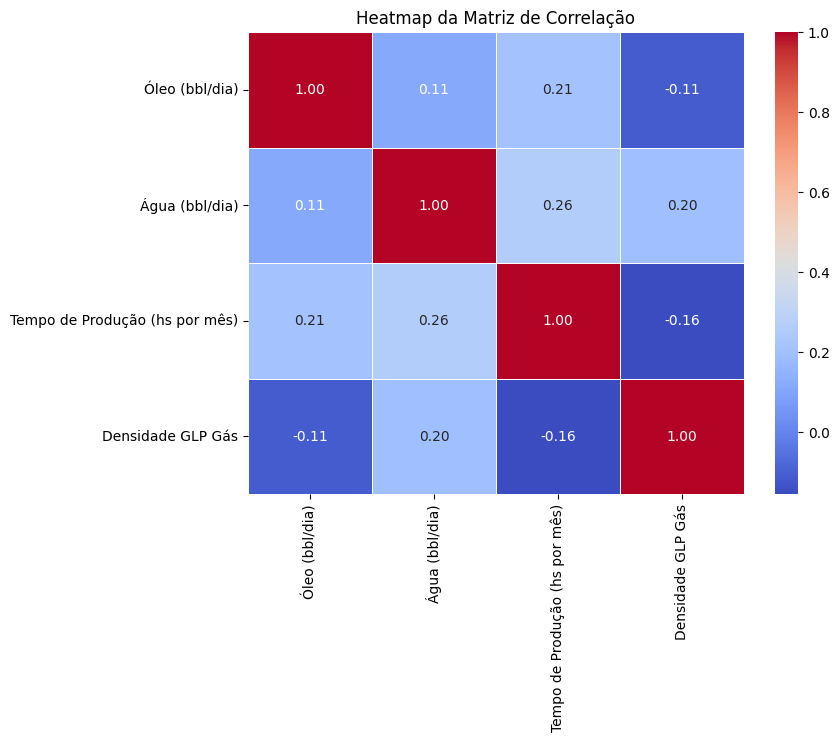

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_matrix = X_train.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=.5,
    cbar=True
)

plt.title('Heatmap da Matriz de Correlação')
plt.show()